In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.utils import compute_class_weight
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

from keras.callbacks import EarlyStopping
from keras.optimizers import Adam
from keras.models import Sequential
from keras.layers import Input, Rescaling, Flatten, Dense, Dropout
from keras.utils import image_dataset_from_directory, set_random_seed

In [23]:
X_train = image_dataset_from_directory('fer2013/train', validation_split=0.2, subset='training', seed=42,
                                       color_mode='grayscale', image_size=(48, 48), batch_size=64)

X_val = image_dataset_from_directory('fer2013/train', validation_split=0.2, subset='validation', seed=42,
                                     color_mode='grayscale', image_size=(48, 48), batch_size=64)

X_test = image_dataset_from_directory('fer2013/test', color_mode='grayscale', image_size=(48, 48),
                                      batch_size=100000, shuffle=False)   # one big batch = the whole test set

class_names = X_train.class_names
class_names

Found 28709 files belonging to 7 classes.
Using 22968 files for training.
Found 28709 files belonging to 7 classes.
Using 5741 files for validation.
Found 7178 files belonging to 7 classes.


['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

## Explore the Dataset

In [24]:
# take one batch of train
images, labels = list(X_train)[0]

# (64 images, 48 height, 48 width, 1 channel -> grayscale)
print(images.shape)
print(labels.shape)

(64, 48, 48, 1)
(64,)


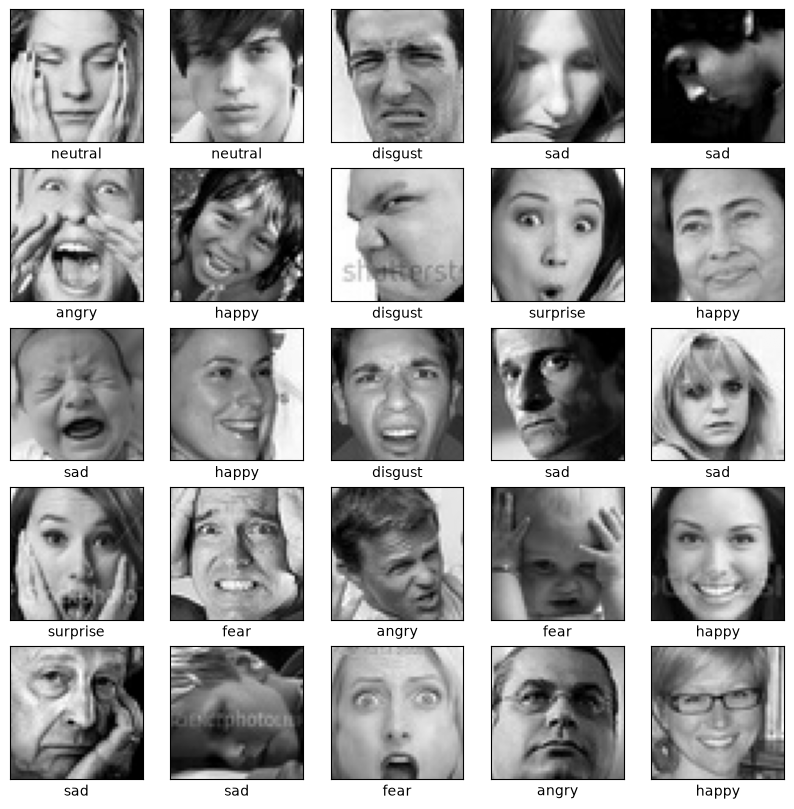

In [25]:
# plot some images
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(images[i].numpy().reshape(48, 48), cmap="gray")
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.xlabel(class_names[labels[i]])
plt.show()

In [26]:
# class distribution: load all the train labels in one batch
all_images, y_train = list(image_dataset_from_directory('fer2013/train', color_mode='grayscale',
                                                        image_size=(48, 48), batch_size=100000))[0]
y_train = y_train.numpy()

counts = pd.Series(y_train).value_counts().sort_index()
counts.index = class_names
counts

Found 28709 files belonging to 7 classes.


angry       3995
disgust      436
fear        4097
happy       7215
neutral     4965
sad         4830
surprise    3171
Name: count, dtype: int64

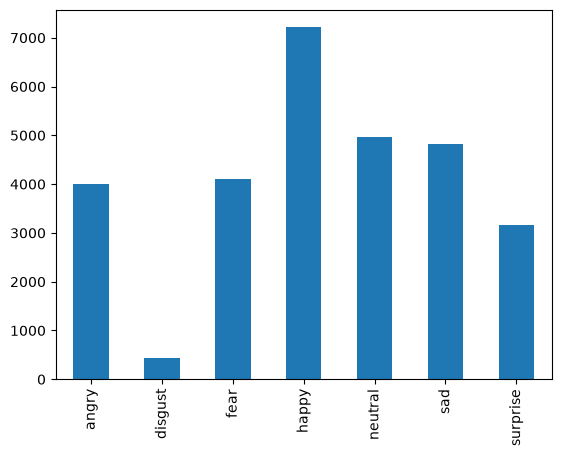

In [27]:
counts.plot(kind='bar');

## Baseline Model (Dense layers)

In [28]:
set_random_seed(9999)

model = Sequential([
                    Input(shape=(48, 48, 1)),
                    Rescaling(1./255),                # normalize
                    Flatten(),                        # converting 2D -> 1D

                    Dense(128, activation='relu'),    # Hidden layer 1
                    Dense(64, activation='relu'),     # Hidden layer 2

                    Dense(7, activation='softmax')    # output layer -> 7 classes -> softmax to get prob
                    ])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)              │ (None, 48, 48, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 128)                 │         295,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 7)                   │             455 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 303,751 (1.16 MB)

 Trainable params: 303,751 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

## Training

In [29]:
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['acc'])

history = model.fit(X_train, validation_data=X_val, epochs=5)

Epoch 1/5


C:\Users\Ali\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


359/359 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - acc: 0.2780 - loss: 1.7853 - val_acc: 0.3128 - val_loss: 1.7670
Epoch 2/5
359/359 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - acc: 0.3249 - loss: 1.7045 - val_acc: 0.3524 - val_loss: 1.6792
Epoch 3/5
359/359 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - acc: 0.3374 - loss: 1.6869 - val_acc: 0.3644 - val_loss: 1.6614
Epoch 4/5
359/359 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - acc: 0.3487 - loss: 1.6589 - val_acc: 0.3546 - val_loss: 1.6507
Epoch 5/5
359/359 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - acc: 0.3605 - loss: 1.6393 - val_acc: 0.3381 - val_loss: 1.6584


In [30]:
# history dataframe
history_df = pd.DataFrame(history.history)
history_df.head()

,acc,loss,val_acc,val_loss
0,0.277995,1.785348,0.312837,1.767024
1,0.324887,1.704538,0.352378,1.679207
2,0.337382,1.686853,0.364396,1.661367
3,0.348659,1.658886,0.354642,1.650736
4,0.360502,1.639269,0.338094,1.658422


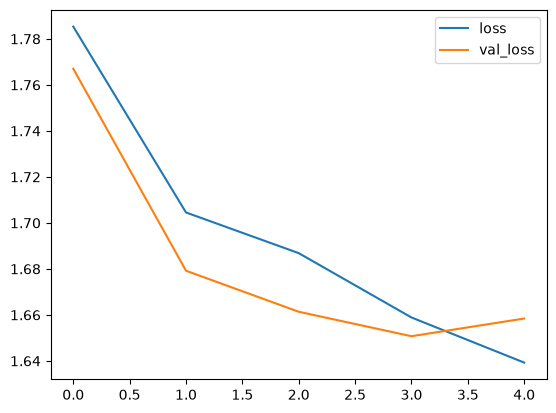

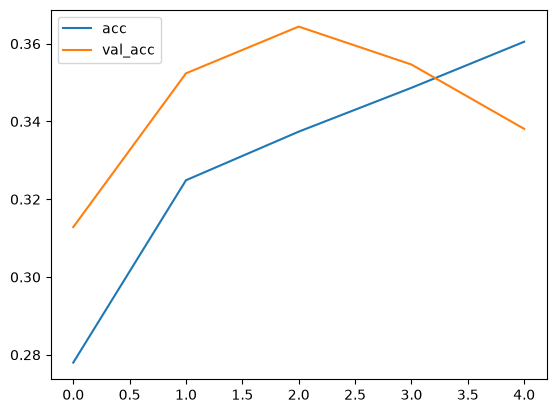

In [31]:
# overfitting? train keeps going up but validation stops or goes down
history_df[['loss', 'val_loss']].plot()
history_df[['acc', 'val_acc']].plot();

## Evaluation on the Test Set

In [32]:
# the test set is one big batch: images and labels
images_test, y_test = list(X_test)[0]
y_test = y_test.numpy()

y_pred_test = model.predict(X_test).argmax(axis=1)
y_pred_test

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


array([3, 3, 3, ..., 3, 6, 6], shape=(7178,))

In [33]:
print(classification_report(y_test, y_pred_test, target_names=class_names))

              precision    recall  f1-score   support

       angry       0.31      0.06      0.11       958
     disgust       0.00      0.00      0.00       111
        fear       0.27      0.03      0.05      1024
       happy       0.32      0.90      0.48      1774
     neutral       0.41      0.16      0.23      1233
         sad       0.33      0.19      0.24      1247
    surprise       0.47      0.43      0.45       831

    accuracy                           0.35      7178
   macro avg       0.30      0.25      0.22      7178
weighted avg       0.34      0.35      0.27      7178



C:\Users\Ali\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Ali\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Ali\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

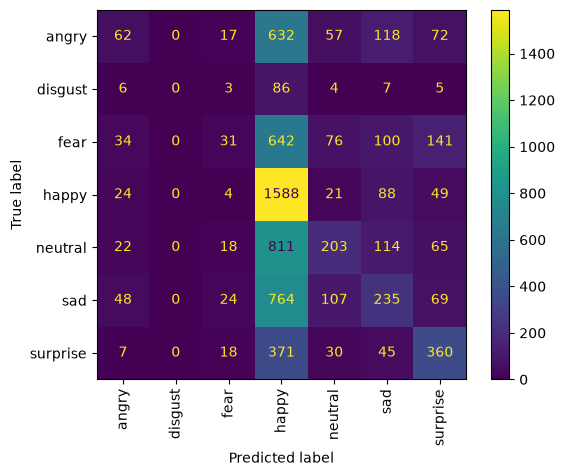

In [34]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, display_labels=class_names, xticks_rotation='vertical');

## Error Analysis

In [35]:
mistakes = y_test != y_pred_test
mistakes.sum()

np.int64(4699)

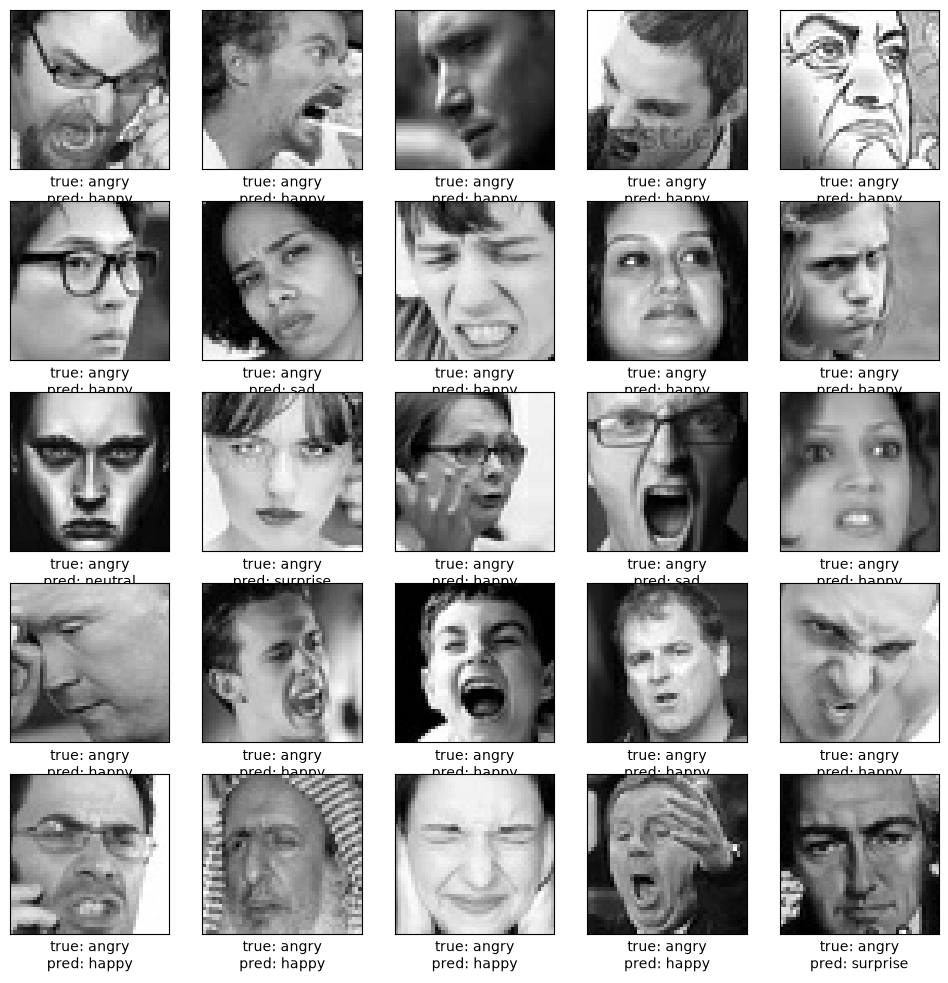

In [36]:
# plot the images the model got wrong
wrong_idx = np.where(mistakes)[0]

plt.figure(figsize=(12, 12))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(images_test[wrong_idx[i]].numpy().reshape(48, 48), cmap="gray")
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.xlabel('true: ' + class_names[y_test[wrong_idx[i]]] + '\npred: ' + class_names[y_pred_test[wrong_idx[i]]])
plt.show()

## Model Improvement

In [37]:
c_weights = compute_class_weight(class_weight="balanced", classes=np.unique(y_train), y=y_train)

class_weight_dict = dict(zip(np.unique(y_train), c_weights))
class_weight_dict

{np.int32(0): np.float64(1.0266046844269623),
 np.int32(1): np.float64(9.406618610747051),
 np.int32(2): np.float64(1.0010460615781582),
 np.int32(3): np.float64(0.5684387684387684),
 np.int32(4): np.float64(0.8260394187886635),
 np.int32(5): np.float64(0.8491274770777877),
 np.int32(6): np.float64(1.293372978330405)}

In [46]:
set_random_seed(9999)

model2 = Sequential([
                     Input(shape=(48, 48, 1)),
                     Rescaling(1./255),
                     Flatten(),

                     Dense(128, activation='relu'),
                     Dense(64, activation='relu'),

                     Dense(7, activation='softmax')
                     ])

model2.compile(loss='sparse_categorical_crossentropy', optimizer=Adam(), metrics=['acc'])

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history2 = model2.fit(X_train, validation_data=X_val, epochs=30, callbacks=[early_stop])

Epoch 1/30


C:\Users\Ali\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


359/359 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - acc: 0.2800 - loss: 1.7797 - val_acc: 0.2947 - val_loss: 1.7386
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - acc: 0.3264 - loss: 1.7051 - val_acc: 0.3353 - val_loss: 1.6809
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - acc: 0.3419 - loss: 1.6757 - val_acc: 0.3280 - val_loss: 1.7172
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - acc: 0.3526 - loss: 1.6537 - val_acc: 0.3519 - val_loss: 1.6501
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - acc: 0.3556 - loss: 1.6395 - val_acc: 0.3625 - val_loss: 1.6274
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - acc: 0.3628 - loss: 1.6262 - val_acc: 0.3602 - val_loss: 1.6282
Epoch 7/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - acc: 0.3668 - loss: 1.6134 - val_acc: 0.3681 - val_loss: 1.6341
Epoch 8/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - acc: 0.3752 - loss: 1.5981 - val_acc: 0.3574 - val_loss: 1.6663


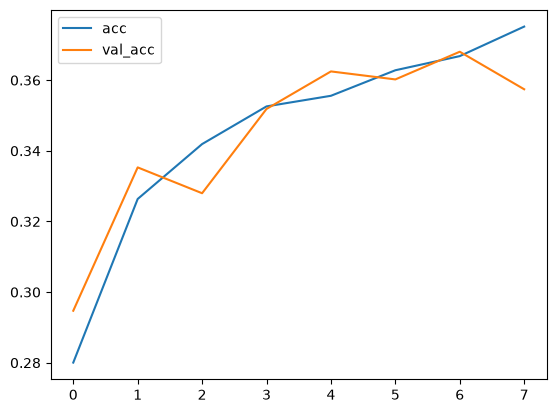

In [47]:
history2_df = pd.DataFrame(history2.history)
history2_df[['acc', 'val_acc']].plot();

In [48]:
y_pred_test2 = model2.predict(X_test).argmax(axis=1)

print(classification_report(y_test, y_pred_test2, target_names=class_names))

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
              precision    recall  f1-score   support

       angry       0.29      0.04      0.07       958
     disgust       0.00      0.00      0.00       111
        fear       0.25      0.03      0.05      1024
       happy       0.41      0.74      0.53      1774
     neutral       0.31      0.49      0.38      1233
         sad       0.36      0.21      0.27      1247
    surprise       0.41      0.52      0.46       831

    accuracy                           0.37      7178
   macro avg       0.29      0.29      0.25      7178
weighted avg       0.34      0.37      0.31      7178



C:\Users\Ali\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Ali\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Ali\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

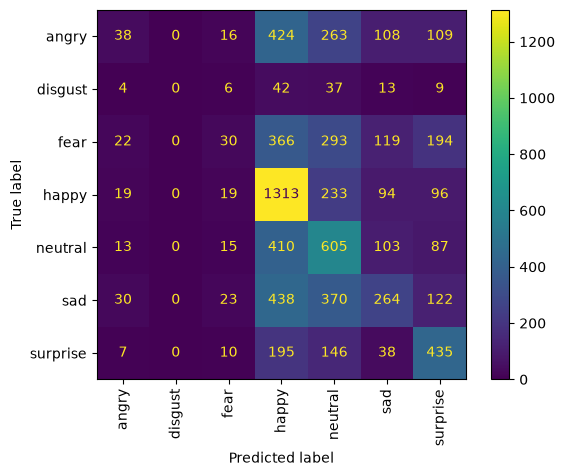

In [49]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test2, display_labels=class_names, xticks_rotation='vertical');

In [42]:
# save the final model for the app
model2.save('emotion_model.keras')